# Phase 8 — Customer Retention Intervention Simulation and Business Impact Analysis

This notebook converts the locked churn model's existing held-out probabilities into a capacity-constrained, retrospective campaign simulation. It does **not** retrain, tune, recalibrate, or modify the model or its Phase 6 threshold. Financial values and intervention effectiveness are explicitly hypothetical.

## 1. Introduction

Prediction and intervention answer different questions. The model estimates relative churn risk; it does not estimate whether an outreach action will prevent churn. This phase measures how well a strict top-20% ranking concentrates historical churners and then combines that measured capture with transparent scenario assumptions.

In [1]:
from pathlib import Path
import hashlib
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image, display

candidate = Path.cwd().resolve()
ROOT = candidate if (candidate / 'src').is_dir() else candidate.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.evaluation import (
    compute_classification_metrics,
    positive_class_probabilities,
    predictions_at_threshold,
)
from src.explainability import file_sha256, load_trusted_locked_model
from src.preprocessing import (
    apply_deterministic_cleaning,
    dataframe_fingerprint,
    load_and_validate_data,
    separate_features_target_ids,
)
from src.retention_simulation import (
    DEFAULT_CONTACT_COST,
    DEFAULT_CONTACT_FRACTION,
    DEFAULT_RETAINED_VALUE,
    DEFAULT_SUCCESS_RATE,
    build_internal_analysis_table,
    calculate_break_even_success_rate,
    calculate_retention_economics,
    calculate_selection_metrics,
    create_strategy_comparison_table,
    cumulative_gains_data,
    exact_random_selection_expectations,
    plot_cumulative_gains,
    plot_financial_comparison,
    plot_lift_comparison,
    plot_sensitivity_analysis,
    plot_strategy_comparison,
    probability_ranking_summary,
    run_sensitivity_scenarios,
    save_aggregate_results,
    simulate_random_selection,
)

sns.set_theme(style='whitegrid', context='talk')
pd.set_option('display.max_columns', 30)

RAW_PATH = ROOT / 'data' / 'raw' / 'customer_churn_advanced_dataset.csv'
CLEANED_PATH = ROOT / 'data' / 'processed' / '02_cleaned_dataset.csv'
SPLIT_PATH = ROOT / 'data' / 'processed' / '02_split_indices.json'
INTERNAL_RANKING_PATH = ROOT / 'data' / 'processed' / 'internal_retention_ranking.csv'
MODEL_PATH = ROOT / 'models' / '03_model_artifact.joblib'
METADATA_PATH = ROOT / 'models' / 'final_model_metadata.json'
PHASE6_METRICS_PATH = ROOT / 'reports' / 'evaluation' / 'phase6_final_test_metrics.json'
PHASE7_INTEGRITY_PATH = ROOT / 'reports' / 'explainability' / 'phase7_integrity.json'
RESULTS_PATH = ROOT / 'reports' / 'retention_simulation_results.csv'
SENSITIVITY_PATH = ROOT / 'reports' / 'retention_sensitivity_analysis.csv'
INTEGRITY_PATH = ROOT / 'reports' / 'retention_simulation_integrity.json'
FIGURE_DIR = ROOT / 'reports' / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

## 2. Business scenario

The retention team can contact at most 20% of the evaluated population. The policy is therefore declared before examining outcomes: rank customers by locked-model churn probability from highest to lowest, break exact probability ties using the original held-out row order, and contact exactly `floor(N × 0.20)` customers. Actual churn labels are attached only after selection for retrospective evaluation.

## 3. Final model and dataset validation

The trusted local artifact is verified against locked metadata before loading. The original dataset, cleaned dataset, saved split, metadata, and model hashes are captured so the final cell can prove they were not changed. The fixed Phase 2 test indices and fingerprint must match both Phase 6 metadata and the cleaned data.

In [2]:
required_paths = (
    RAW_PATH, CLEANED_PATH, SPLIT_PATH, MODEL_PATH, METADATA_PATH,
    PHASE6_METRICS_PATH, PHASE7_INTEGRITY_PATH,
)
missing = [str(path) for path in required_paths if not path.is_file()]
assert not missing, f'Missing prerequisite artifacts: {missing}'

hashes_before = {path.name: file_sha256(path) for path in required_paths}
metadata = json.loads(METADATA_PATH.read_text(encoding='utf-8'))
split = json.loads(SPLIT_PATH.read_text(encoding='utf-8'))
phase6_metrics = json.loads(PHASE6_METRICS_PATH.read_text(encoding='utf-8'))
phase7_integrity = json.loads(PHASE7_INTEGRITY_PATH.read_text(encoding='utf-8'))

assert file_sha256(MODEL_PATH) == metadata['model_artifact_sha256']
assert file_sha256(SPLIT_PATH) == metadata['split_artifact_sha256']
assert split['dataset_fingerprint'] == metadata['dataset_fingerprint']
assert split['random_state'] == metadata['random_seed'] == 42
assert len(split['test_indices']) == metadata['test_rows'] == 240
assert set(split['train_indices']).isdisjoint(split['test_indices'])

cleaned = apply_deterministic_cleaning(load_and_validate_data(CLEANED_PATH))
assert dataframe_fingerprint(cleaned) == metadata['dataset_fingerprint']
train_df = cleaned.loc[split['train_indices']].copy()
test_df = cleaned.loc[split['test_indices']].copy()
X_train, y_train, _train_ids = separate_features_target_ids(train_df)
X_test, y_test, _test_ids = separate_features_target_ids(test_df)
assert len(X_train) == 960 and len(X_test) == 240
assert set(X_train.index).isdisjoint(X_test.index)
assert 'customer_id' not in X_test and 'churn' not in X_test

model = load_trusted_locked_model(
    MODEL_PATH,
    expected_sha256=metadata['model_artifact_sha256'],
    trusted=True,
)
assert model.classes_.tolist() == [0, 1]
threshold = float(metadata['operating_threshold'])
print(f"Validated {type(model).__name__}; test rows={len(X_test)}; threshold={threshold:.12f}")

Validated CalibratedClassifierCV; test rows=240; threshold=0.970709000432


## 4. Predicted churn probabilities

Label 1 is the positive churn class. Each score lies between zero and one and is an estimated model probability—not a guaranteed outcome. The test probabilities must reproduce the Phase 7 hash and Phase 6 metrics exactly.

In [3]:
probabilities = positive_class_probabilities(model, X_test)
assert len(probabilities) == len(X_test)
assert np.isfinite(probabilities).all()
assert ((probabilities >= 0) & (probabilities <= 1)).all()
probability_hash = hashlib.sha256(probabilities.tobytes()).hexdigest()
assert probability_hash == phase7_integrity['prediction_hash_after']

locked_predictions = predictions_at_threshold(probabilities, threshold)
reproduced_metrics = compute_classification_metrics(y_test, probabilities, threshold=threshold)
for metric in ('accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'average_precision'):
    assert np.isclose(reproduced_metrics[metric], phase6_metrics['selected_business_threshold'][metric])
print(f'Positive class: churn=1; probability hash: {probability_hash}')

Positive class: churn=1; probability hash: 4e95bae1a6bff60cfdb7a8b2161716e31555cdbcc7ca73d003109a926219e1ae


## 5. Customer risk ranking

Scores are sorted descending. Ties are not modified: the existing held-out order is the sole secondary key. This key is independent of the target and customer identity. The protected table uses synthetic row references rather than raw customer IDs.

In [4]:
ranking_summary = probability_ranking_summary(probabilities)
internal_ranking = build_internal_analysis_table(
    probabilities,
    y_test.to_numpy(),
    locked_predictions,
    contact_fraction=DEFAULT_CONTACT_FRACTION,
)
INTERNAL_RANKING_PATH.parent.mkdir(parents=True, exist_ok=True)
internal_ranking.to_csv(INTERNAL_RANKING_PATH, index=False)
assert 'customer_id' not in internal_ranking.columns
assert internal_ranking['predicted_churn_probability'].is_monotonic_decreasing
display(pd.DataFrame([ranking_summary]))

,total_customers,minimum_probability,maximum_probability,mean_probability,median_probability,unique_probabilities,tied_score_groups,customers_with_tied_scores
0,240,0.245218,0.980746,0.871795,0.962813,240,0,0


## 6. Top-20% customer selection

Capacity uses `floor(N × 0.20)`, so it can never be exceeded. This ranking policy is intentionally separate from the unchanged Phase 6 probability threshold; the threshold is not moved to force a 20% contact rate.

In [5]:
selection_metrics = calculate_selection_metrics(
    internal_ranking['actual_churn'],
    internal_ranking['selected_top_20pct'],
)
expected_contact_count = int(np.floor(len(X_test) * DEFAULT_CONTACT_FRACTION))
assert selection_metrics['selected_customers'] == expected_contact_count
assert selection_metrics['contact_rate'] <= DEFAULT_CONTACT_FRACTION
capacity_table = pd.DataFrame([
    {'metric': 'Total evaluated customers', 'value': selection_metrics['total_customers']},
    {'metric': 'Maximum/selected contacts', 'value': selection_metrics['selected_customers']},
    {'metric': 'Actual selected percentage', 'value': selection_metrics['actual_selected_percentage']},
    {'metric': 'Churners inside selected group', 'value': selection_metrics['selected_churners']},
    {'metric': 'Non-churners inside selected group', 'value': selection_metrics['selected_non_churners']},
    {'metric': 'Churners outside selected group', 'value': selection_metrics['outside_churners']},
    {'metric': 'Total actual churners', 'value': selection_metrics['total_actual_churners']},
])
display(capacity_table)

,metric,value
0,Total evaluated customers,240.0
1,Maximum/selected contacts,48.0
2,Actual selected percentage,20.0
3,Churners inside selected group,48.0
4,Non-churners inside selected group,0.0
5,Churners outside selected group,159.0
6,Total actual churners,207.0


## 7. Churner capture analysis

The selected group is evaluated only after ranking. “Captured” means an observed churner appears in the contact list; it does not mean that churn would actually be prevented.

In [6]:
capture_table = pd.DataFrame({
    'group': ['Selected top 20%', 'Outside selected group'],
    'customers': [
        selection_metrics['selected_customers'],
        selection_metrics['total_customers'] - selection_metrics['selected_customers'],
    ],
    'actual_churners': [
        selection_metrics['selected_churners'],
        selection_metrics['outside_churners'],
    ],
})
display(capture_table)

,group,customers,actual_churners
0,Selected top 20%,48,48
1,Outside selected group,192,159


## 8. Random selection baseline

The exact random expectation uses the same 48-contact budget. For a population of `N` with `C` churners and `k` contacts, expected captured churners are `k × C / N`. A 10,000-run simulation without replacement (seed 42) is included only as a variability illustration; the exact expectation is the primary baseline.

In [7]:
random_expectations = exact_random_selection_expectations(
    selection_metrics['total_customers'],
    selection_metrics['selected_customers'],
    selection_metrics['total_actual_churners'],
)
random_simulation = simulate_random_selection(
    y_test.to_numpy(),
    selection_metrics['selected_customers'],
    n_simulations=10_000,
    random_state=42,
)
monte_carlo_summary = {
    'simulations': len(random_simulation),
    'mean_churners_captured': float(random_simulation['churners_captured'].mean()),
    'std_churners_captured': float(random_simulation['churners_captured'].std(ddof=1)),
    'minimum_churners_captured': int(random_simulation['churners_captured'].min()),
    'maximum_churners_captured': int(random_simulation['churners_captured'].max()),
}
comparison = create_strategy_comparison_table(selection_metrics, random_expectations)
display(comparison)
display(pd.DataFrame([monte_carlo_summary]))

,strategy,contact_count,churners_captured,precision_at_20,recall_at_20,lift_vs_random
0,Model-ranked top 20%,48,48.0,1.0000,0.231884,1.15942
1,Uniform random expectation,48,41.4,0.8625,0.200000,1.00000


,simulations,mean_churners_captured,std_churners_captured,minimum_churners_captured,maximum_churners_captured
0,10000,41.4133,2.130478,32,48


## 9. Precision@20% and Recall@20%

**Precision@20%** is the share of contacted customers who historically churned. **Recall@20%**, also called capture rate here, is the share of all historical churners included within the contact budget. These ranking metrics are not the Phase 6 classification precision and recall at threshold 0.970709.

,strategy,contact_count,churners_captured,precision_at_20,recall_at_20,lift_vs_random
0,Model-ranked top 20%,48,48.00,1.0000,0.2319,1.1594
1,Uniform random expectation,48,41.40,0.8625,0.2000,1.0000


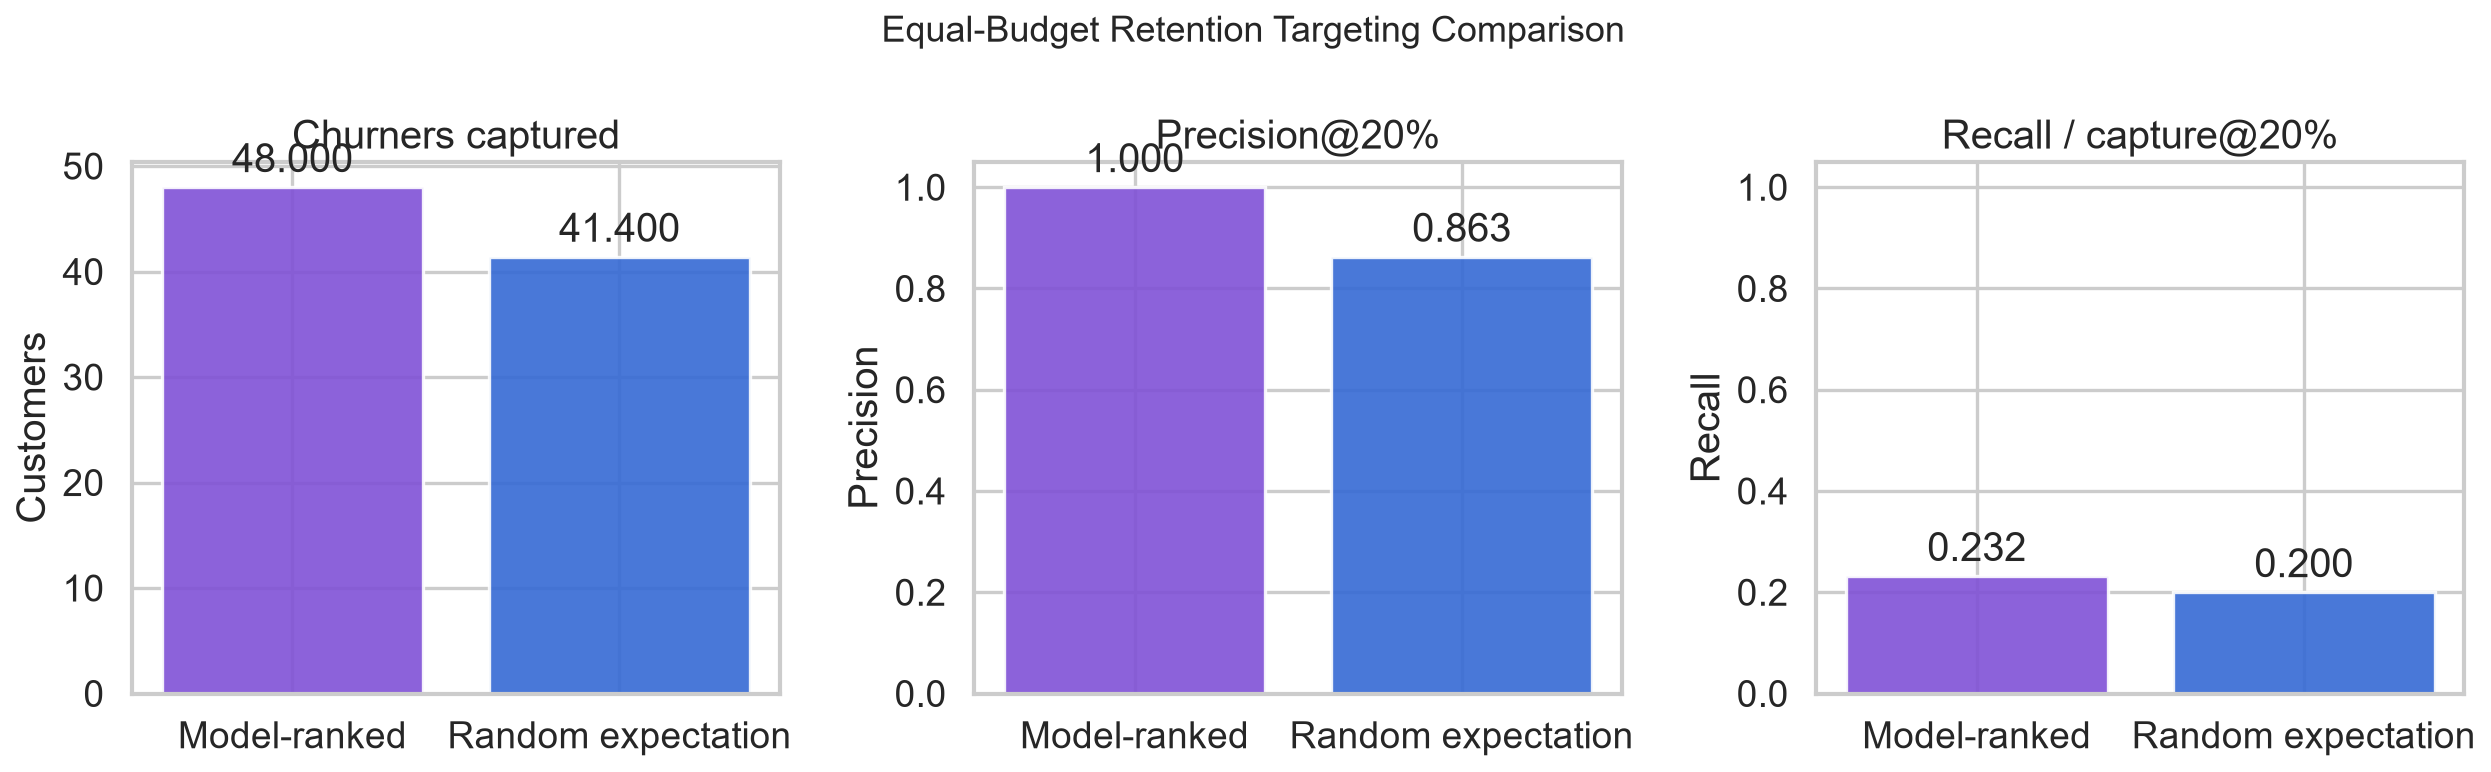

In [8]:
metric_comparison = comparison[[
    'strategy', 'contact_count', 'churners_captured',
    'precision_at_20', 'recall_at_20', 'lift_vs_random',
]]
display(metric_comparison.style.format({
    'churners_captured': '{:.2f}',
    'precision_at_20': '{:.4f}',
    'recall_at_20': '{:.4f}',
    'lift_vs_random': '{:.4f}',
}))

comparison_figure = FIGURE_DIR / 'phase8_model_vs_random_capture.png'
plot_strategy_comparison(comparison, comparison_figure)
display(Image(filename=str(comparison_figure)))

The comparison uses equal contact counts. Any advantage therefore comes from concentration in the ranking, not from spending more contacts.

## 10. Ranking lift

Lift is `model precision@20% / overall churn prevalence`. A lift above one means the selected group contains churners at a higher rate than uniform random selection. Because overall churn prevalence is already high, the maximum available lift is limited.

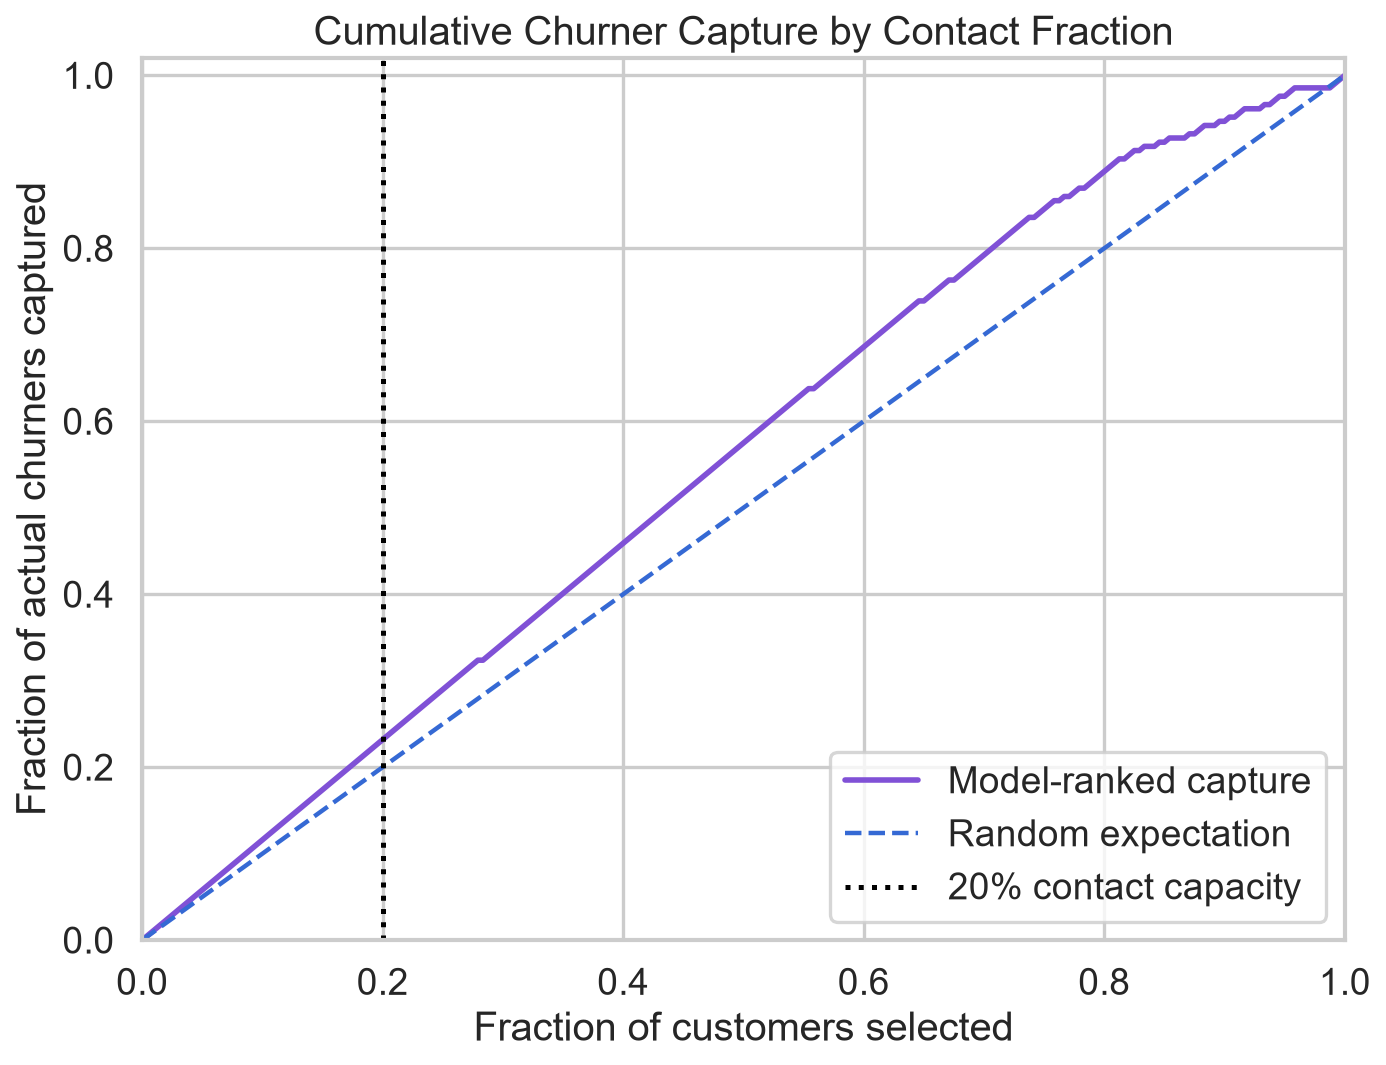

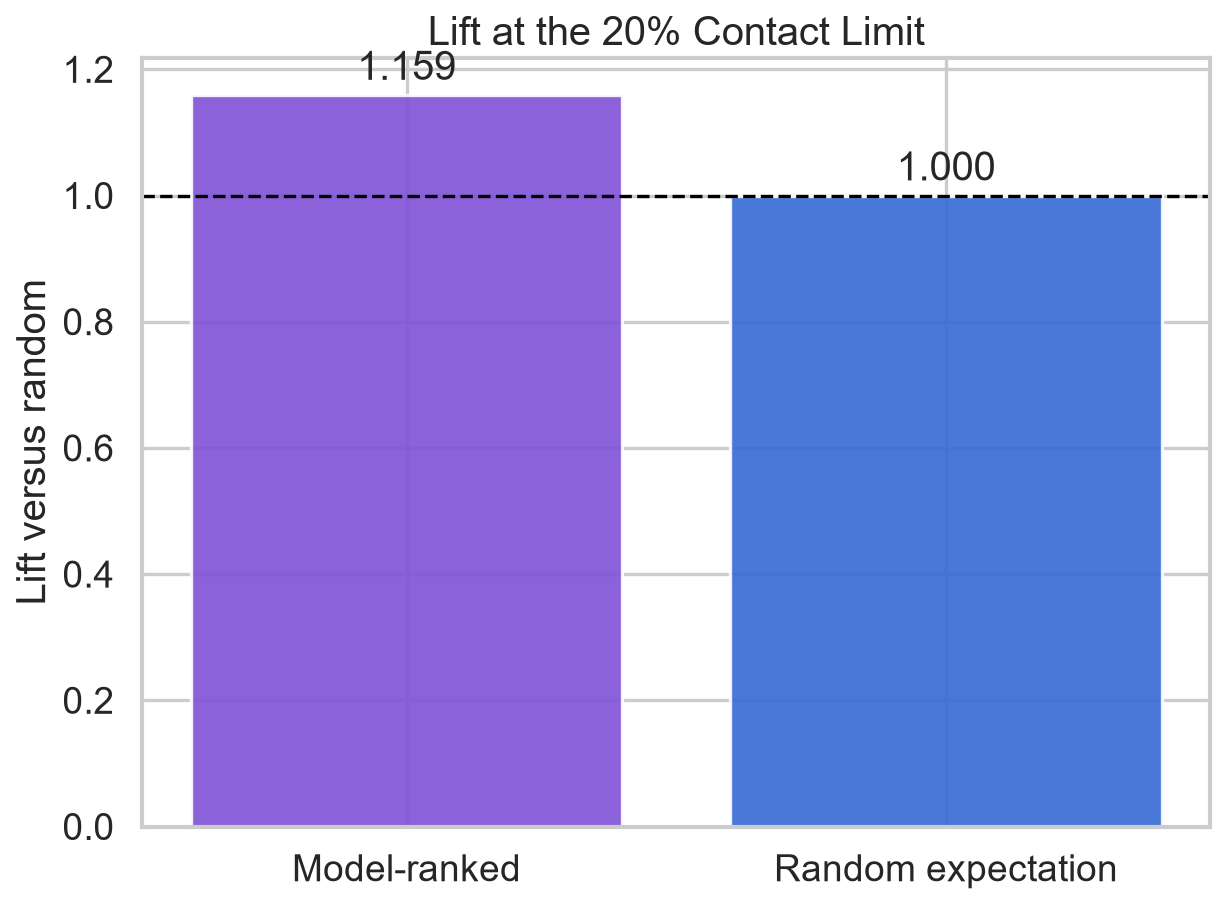

In [9]:
gains = cumulative_gains_data(y_test.to_numpy(), probabilities)
gains_figure = FIGURE_DIR / 'phase8_cumulative_gains.png'
lift_figure = FIGURE_DIR / 'phase8_lift_comparison.png'
plot_cumulative_gains(gains, gains_figure)
plot_lift_comparison(comparison, lift_figure)
display(Image(filename=str(gains_figure)))
display(Image(filename=str(lift_figure)))

The cumulative-gains curve compares ranked capture with the diagonal random expectation and marks the fixed 20% capacity. The lift chart expresses the same concentration relative to a random baseline of one.

## 11. Cost-benefit assumptions

The dataset contains no campaign costs, retained-customer value, or measured treatment outcomes. The following values are illustrative USD accounting assumptions only:

- Contact cost: **$5 per selected customer**
- Value of retaining one would-be churner: **$150**
- Intervention success rate among contacted customers who otherwise would churn: **10%**
- Contact capacity: **20%**

The simulation assumes the historical churn label approximates the no-intervention outcome. This is unverified. The 10% rate is not an estimated causal effect.

## 12. Financial simulation

Both strategies use the same contact count and unit assumptions. Expected retained customers may be fractional because they are scenario expectations, not confirmed people. Net benefit is gross retained-customer value minus contact cost; ROI is net benefit divided by contact cost.

,strategy,captured_churners,contact_count,cost_per_contact,value_per_retained_customer,intervention_success_rate,total_contact_cost,expected_retained_customers,expected_gross_value,expected_net_benefit,roi_percent,roi_defined
0,Model-ranked top 20%,48.0,48,5.0,150.0,0.1,240.0,4.80,720.0,480.0,200.00,True
1,Uniform random expectation,41.4,48,5.0,150.0,0.1,240.0,4.14,621.0,381.0,158.75,True


Incremental expected net benefit: $99.00


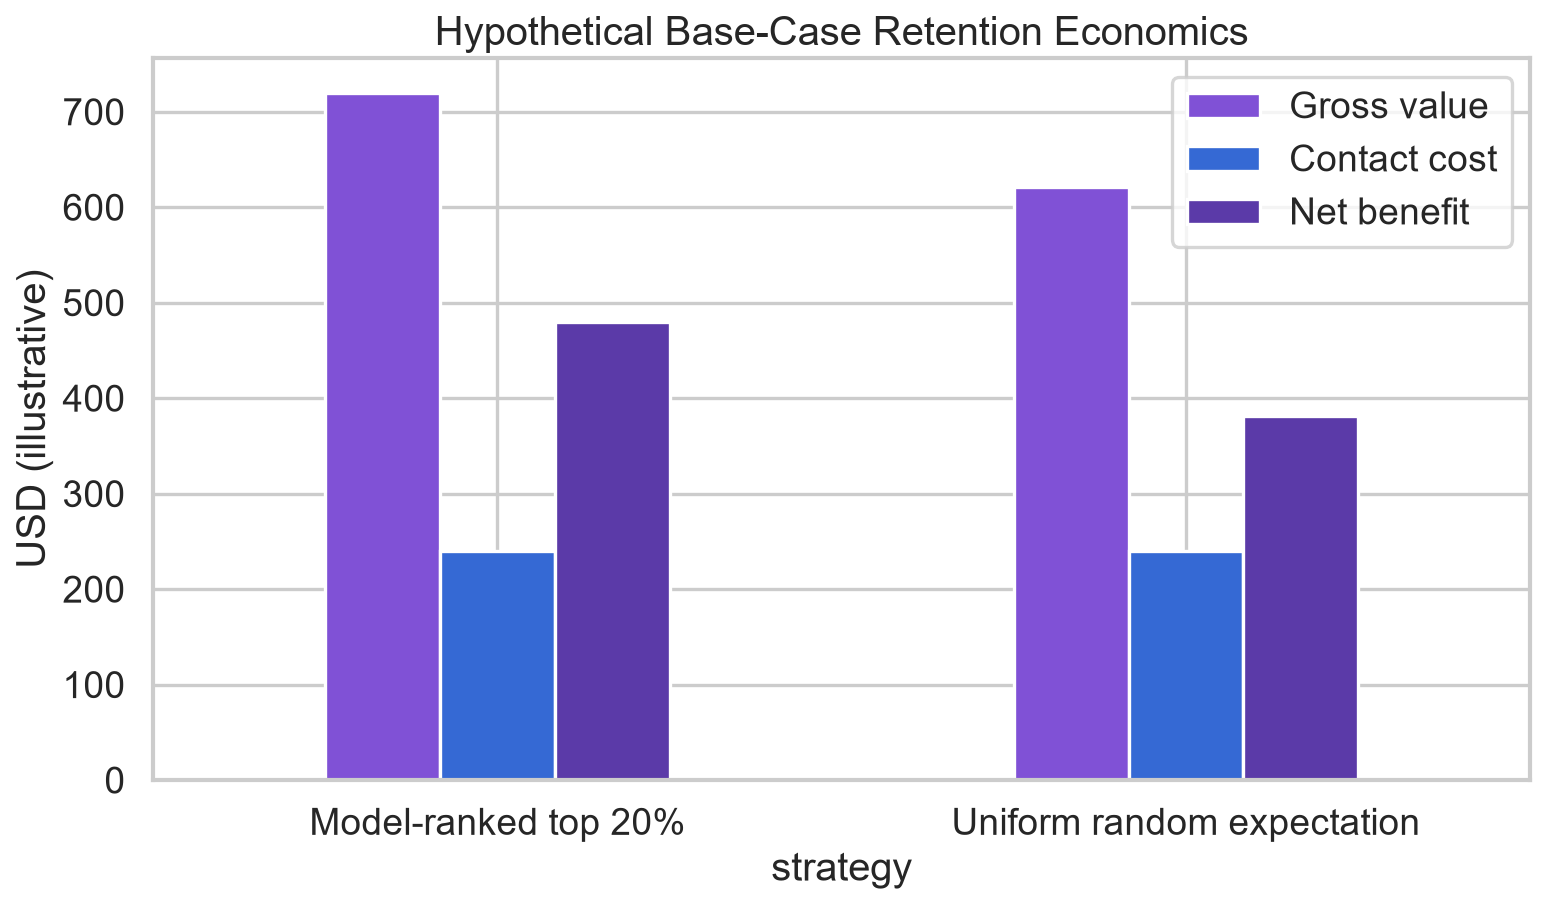

In [10]:
model_economics = calculate_retention_economics(
    selection_metrics['selected_churners'],
    selection_metrics['selected_customers'],
    cost_per_contact=DEFAULT_CONTACT_COST,
    value_per_retained_customer=DEFAULT_RETAINED_VALUE,
    intervention_success_rate=DEFAULT_SUCCESS_RATE,
)
random_economics = calculate_retention_economics(
    random_expectations['expected_churners_captured'],
    selection_metrics['selected_customers'],
    cost_per_contact=DEFAULT_CONTACT_COST,
    value_per_retained_customer=DEFAULT_RETAINED_VALUE,
    intervention_success_rate=DEFAULT_SUCCESS_RATE,
)
incremental_net_benefit = (
    model_economics['expected_net_benefit']
    - random_economics['expected_net_benefit']
)
economics = pd.DataFrame([
    {'strategy': 'Model-ranked top 20%', **model_economics},
    {'strategy': 'Uniform random expectation', **random_economics},
])
display(economics)
print(f'Incremental expected net benefit: ${incremental_net_benefit:,.2f}')

financial_figure = FIGURE_DIR / 'phase8_financial_comparison.png'
plot_financial_comparison(economics, financial_figure)
display(Image(filename=str(financial_figure)))

These dollar results combine observed retrospective churn outcomes with hypothetical success, cost, and value assumptions. They are scenario estimates, not realized savings or proof of campaign effectiveness.

## 13. Scenario and sensitivity analysis

A 27-scenario grid varies intervention effectiveness (5%, 10%, 20%), contact cost ($2, $5, $10), and retained-customer value ($75, $150, $300). The selected customer ranking remains fixed; final-test labels are not used to redesign the policy.

,scenario_id,intervention_success_rate,cost_per_contact,value_per_retained_customer,model_expected_retained_customers,random_expected_retained_customers,model_expected_net_benefit,random_expected_net_benefit,incremental_expected_net_benefit,model_roi_percent,random_roi_percent,model_financially_attractive,random_financially_attractive
4,5,0.05,5.0,150.0,2.4,2.07,120.0,70.5,49.5,50.0,29.375,True,True
13,14,0.10,5.0,150.0,4.8,4.14,480.0,381.0,99.0,200.0,158.750,True,True
22,23,0.20,5.0,150.0,9.6,8.28,1200.0,1002.0,198.0,500.0,417.500,True,True


Model break-even success rate: 3.3333%
Random break-even success rate: 3.8647%


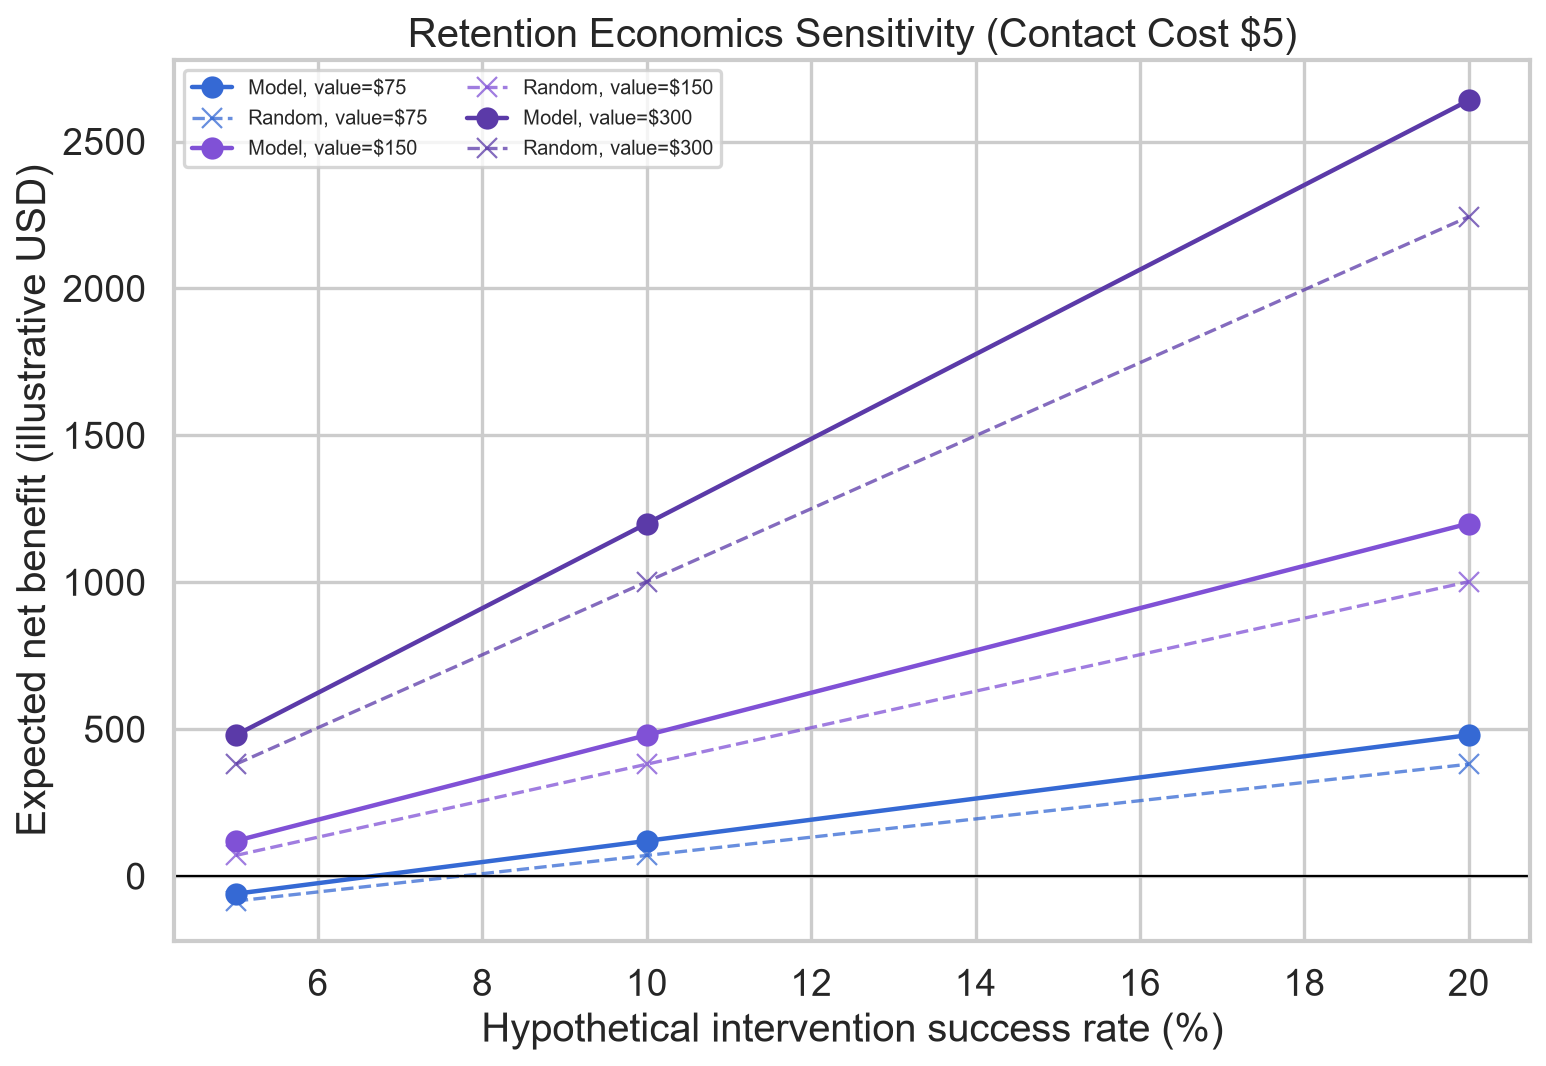

In [11]:
sensitivity = run_sensitivity_scenarios(
    selection_metrics['selected_churners'],
    random_expectations['expected_churners_captured'],
    selection_metrics['selected_customers'],
)
save_aggregate_results(sensitivity, SENSITIVITY_PATH)
base_value_scenarios = sensitivity.loc[
    np.isclose(sensitivity['cost_per_contact'], DEFAULT_CONTACT_COST)
    & np.isclose(sensitivity['value_per_retained_customer'], DEFAULT_RETAINED_VALUE)
].copy()
display(base_value_scenarios)

model_break_even = calculate_break_even_success_rate(
    selection_metrics['selected_churners'],
    selection_metrics['selected_customers'],
)
random_break_even = calculate_break_even_success_rate(
    random_expectations['expected_churners_captured'],
    selection_metrics['selected_customers'],
)
print(f'Model break-even success rate: {model_break_even:.4%}')
print(f'Random break-even success rate: {random_break_even:.4%}')

sensitivity_figure = FIGURE_DIR / 'phase8_sensitivity_analysis.png'
plot_sensitivity_analysis(sensitivity, sensitivity_figure)
display(Image(filename=str(sensitivity_figure)))

Positive base-case results are conditional on the assumptions. Scenarios can become unattractive when outreach is costly, retained-customer value is low, or treatment effectiveness is weak. Break-even rates indicate the minimum assumed effectiveness for zero expected net benefit under the base cost and value.

## 14. Business recommendations

The following are candidates for randomized pilot testing, not proven treatments. Eligibility and treatment choice should use permissible operational rules rather than protected or sensitive characteristics.

In [12]:
interventions = pd.DataFrame([
    {
        'observed_supporting_evidence': 'Monthly usage is the dominant permutation-importance signal and high-usage groups have high fitted risk.',
        'proposed_intervention': 'Service-quality and plan-fit review',
        'intended_group': 'Top-ranked eligible customers with unusually high usage',
        'expected_mechanism': 'Identify congestion, reliability, or plan mismatch before renewal.',
        'assumptions': 'Usage is timely and an addressable service issue exists.',
        'costs_or_risks': 'Technical review cost; unnecessary contact; correlation is not causation.',
        'success_metrics': 'Randomized uplift in retained accounts, issue resolution, complaint rate.',
    },
    {
        'observed_supporting_evidence': 'Satisfaction contributes to ranking and lower satisfaction was associated with elevated risk.',
        'proposed_intervention': 'Proactive support and complaint resolution',
        'intended_group': 'Top-ranked eligible customers with low satisfaction or unresolved complaints',
        'expected_mechanism': 'Resolve service friction and restore confidence.',
        'assumptions': 'Recorded issues are current and support can resolve them.',
        'costs_or_risks': 'Agent time; poor outreach could worsen satisfaction.',
        'success_metrics': 'Resolution time, satisfaction change, incremental retention uplift.',
    },
    {
        'observed_supporting_evidence': 'Recent late payments add measurable model information.',
        'proposed_intervention': 'Optional payment-support outreach',
        'intended_group': 'Top-ranked eligible customers with recent payment difficulty',
        'expected_mechanism': 'Offer reminders or approved payment arrangements that reduce involuntary loss.',
        'assumptions': 'Support options are compliant, affordable, and voluntarily accepted.',
        'costs_or_risks': 'Privacy, fairness, credit-policy, and adverse-customer-experience risks.',
        'success_metrics': 'Payment completion, arrangement uptake, incremental retention, complaint rate.',
    },
    {
        'observed_supporting_evidence': 'Contract type is the second-ranked global input; month-to-month customers have higher observed scores.',
        'proposed_intervention': 'Contract and renewal assistance',
        'intended_group': 'Top-ranked eligible month-to-month customers approaching a decision point',
        'expected_mechanism': 'Clarify plan options and offer a suitable voluntary renewal path.',
        'assumptions': 'A suitable plan exists and offer economics are sustainable.',
        'costs_or_risks': 'Discount leakage, lock-in concerns, and unequal offer treatment.',
        'success_metrics': 'Offer acceptance, margin-adjusted incremental retention, opt-out rate.',
    },
])
display(interventions)

,observed_supporting_evidence,proposed_intervention,intended_group,expected_mechanism,assumptions,costs_or_risks,success_metrics
0,Monthly usage is the dominant permutation-impo...,Service-quality and plan-fit review,Top-ranked eligible customers with unusually h...,"Identify congestion, reliability, or plan mism...",Usage is timely and an addressable service iss...,Technical review cost; unnecessary contact; co...,"Randomized uplift in retained accounts, issue ..."
1,Satisfaction contributes to ranking and lower ...,Proactive support and complaint resolution,Top-ranked eligible customers with low satisfa...,Resolve service friction and restore confidence.,Recorded issues are current and support can re...,Agent time; poor outreach could worsen satisfa...,"Resolution time, satisfaction change, incremen..."
2,Recent late payments add measurable model info...,Optional payment-support outreach,Top-ranked eligible customers with recent paym...,Offer reminders or approved payment arrangemen...,"Support options are compliant, affordable, and...","Privacy, fairness, credit-policy, and adverse-...","Payment completion, arrangement uptake, increm..."
3,Contract type is the second-ranked global inpu...,Contract and renewal assistance,Top-ranked eligible month-to-month customers a...,Clarify plan options and offer a suitable volu...,A suitable plan exists and offer economics are...,"Discount leakage, lock-in concerns, and unequa...","Offer acceptance, margin-adjusted incremental ..."


## 15. Limitations and operational deployment

A conceptual campaign workflow is:

1. Collect current, consented customer data and validate the required schema.
2. Generate probabilities with the unchanged saved model.
3. Rank scores descending with a predeclared, label-independent tie-breaker.
4. Select the top 20% within capacity.
5. Apply eligibility, privacy, fairness, and business constraints.
6. Assign an approved intervention without using unsupported sensitive-attribute rules.
7. Record assignment, contact, cost, outcome, and opt-out information.
8. Estimate causal uplift through a randomized holdout before scaling.
9. Monitor data quality, drift, calibration, ranking performance, capacity, and subgroup outcomes.

Key limitations are the small 240-row retrospective sample, high churn prevalence, absence of treatment/outcome data, hypothetical economics, possible predictor-timing issues, and no external or temporal validation. Risk scores identify likely churners, not persuadable customers. Production use requires consent, access controls, data-quality monitoring, fairness review, and campaign governance. No API, application, database, or live deployment is built here.

## 16. Final summary and integrity verification

Aggregate public outputs are saved below. The protected ranking stays under the Git-ignored `data/processed/` path and contains no raw customer ID. Final assertions verify equal budgets, label-independent selection, unchanged predictions and hashes, and the original model, metadata, data, and split.

In [13]:
aggregate_rows = []
def add_result(metric, value, unit, result_type, description):
    aggregate_rows.append({
        'metric': metric,
        'value': value,
        'unit': unit,
        'result_type': result_type,
        'description': description,
    })

for metric, value in ranking_summary.items():
    add_result(metric, value, 'count' if 'probability' not in metric else 'probability', 'measured', 'Locked held-out score summary')
for metric in (
    'selected_customers', 'actual_selected_percentage', 'selected_churners',
    'selected_non_churners', 'outside_churners', 'total_actual_churners',
    'precision_at_20', 'recall_at_20', 'lift_at_20',
):
    unit = 'percent' if metric == 'actual_selected_percentage' else ('ratio' if metric in {'precision_at_20', 'recall_at_20', 'lift_at_20'} else 'count')
    add_result(metric, selection_metrics[metric], unit, 'measured', 'Model-ranked top-20% retrospective result')
add_result('random_expected_churners_captured', random_expectations['expected_churners_captured'], 'expected count', 'exact expectation', 'Uniform random selection with equal contact budget')
add_result('random_expected_precision_at_20', random_expectations['expected_random_precision'], 'ratio', 'exact expectation', 'Uniform random selection')
add_result('random_expected_recall_at_20', random_expectations['expected_random_recall'], 'ratio', 'exact expectation', 'Uniform random selection')
add_result('monte_carlo_mean_churners_captured', monte_carlo_summary['mean_churners_captured'], 'simulated count', 'simulation', '10,000 samples without replacement, seed 42')
add_result('contact_cost_per_customer', DEFAULT_CONTACT_COST, 'hypothetical USD', 'assumption', 'Illustrative, not company data')
add_result('value_per_retained_customer', DEFAULT_RETAINED_VALUE, 'hypothetical USD', 'assumption', 'Illustrative, not company data')
add_result('intervention_success_rate', DEFAULT_SUCCESS_RATE, 'assumed ratio', 'assumption', 'Not a measured causal effect')
add_result('model_expected_net_benefit', model_economics['expected_net_benefit'], 'hypothetical USD', 'scenario estimate', 'Observed capture plus base assumptions')
add_result('random_expected_net_benefit', random_economics['expected_net_benefit'], 'hypothetical USD', 'scenario estimate', 'Exact random capture expectation plus base assumptions')
add_result('incremental_expected_net_benefit', incremental_net_benefit, 'hypothetical USD', 'scenario estimate', 'Model minus random under equal assumptions')
add_result('model_roi_percent', model_economics['roi_percent'], 'percent', 'scenario estimate', 'Base assumptions')
add_result('random_roi_percent', random_economics['roi_percent'], 'percent', 'scenario estimate', 'Base assumptions')
add_result('model_break_even_success_rate', model_break_even, 'ratio', 'scenario estimate', 'Base cost and retained value')
add_result('random_break_even_success_rate', random_break_even, 'ratio', 'scenario estimate', 'Base cost and retained value')
aggregate_results = pd.DataFrame(aggregate_rows)
save_aggregate_results(aggregate_results, RESULTS_PATH)

probabilities_after = positive_class_probabilities(model, X_test)
counterfactual_labels = 1 - y_test.to_numpy()
label_independence_check = build_internal_analysis_table(
    probabilities,
    counterfactual_labels,
    locked_predictions,
    contact_fraction=DEFAULT_CONTACT_FRACTION,
)
assert internal_ranking[['risk_rank', 'selected_top_20pct']].equals(
    label_independence_check[['risk_rank', 'selected_top_20pct']]
)
assert comparison['contact_count'].nunique() == 1
assert selection_metrics['selected_customers'] == 48
assert hashlib.sha256(probabilities_after.tobytes()).hexdigest() == probability_hash
assert file_sha256(MODEL_PATH) == hashes_before[MODEL_PATH.name] == metadata['model_artifact_sha256']
assert file_sha256(METADATA_PATH) == hashes_before[METADATA_PATH.name]
assert file_sha256(SPLIT_PATH) == hashes_before[SPLIT_PATH.name]
assert file_sha256(RAW_PATH) == hashes_before[RAW_PATH.name]
assert file_sha256(CLEANED_PATH) == hashes_before[CLEANED_PATH.name]
assert not ({'customer_id', 'internal_row_reference', 'actual_churn', 'predicted_churn_probability'} & set(aggregate_results.columns))
assert not ({'customer_id', 'internal_row_reference', 'actual_churn', 'predicted_churn_probability'} & set(sensitivity.columns))

integrity = {
    'phase': 8,
    'notebook_completed': True,
    'model_retrained_or_tuned': False,
    'model_artifact_sha256_before': hashes_before[MODEL_PATH.name],
    'model_artifact_sha256_after': file_sha256(MODEL_PATH),
    'model_artifact_unchanged': file_sha256(MODEL_PATH) == hashes_before[MODEL_PATH.name],
    'metadata_unchanged': file_sha256(METADATA_PATH) == hashes_before[METADATA_PATH.name],
    'raw_dataset_unchanged': file_sha256(RAW_PATH) == hashes_before[RAW_PATH.name],
    'cleaned_dataset_unchanged': file_sha256(CLEANED_PATH) == hashes_before[CLEANED_PATH.name],
    'split_artifact_unchanged': file_sha256(SPLIT_PATH) == hashes_before[SPLIT_PATH.name],
    'dataset_fingerprint': dataframe_fingerprint(cleaned),
    'prediction_hash_before': probability_hash,
    'prediction_hash_after': hashlib.sha256(probabilities_after.tobytes()).hexdigest(),
    'predictions_unchanged': np.array_equal(probabilities, probabilities_after),
    'operating_threshold': threshold,
    'threshold_unchanged': threshold == metadata['operating_threshold'],
    'test_rows': len(X_test),
    'contact_fraction': DEFAULT_CONTACT_FRACTION,
    'contact_count': selection_metrics['selected_customers'],
    'capacity_respected': selection_metrics['contact_rate'] <= DEFAULT_CONTACT_FRACTION,
    'tie_breaker': 'original held-out order; does not use target or customer ID',
    'selection_label_independent': True,
    'model_and_random_contact_budget_equal': comparison['contact_count'].nunique() == 1,
    'public_customer_level_data_saved': False,
    'internal_ranking_git_ignored': True,
    'hypothetical_assumptions_explicit': True,
}
INTEGRITY_PATH.write_text(json.dumps(integrity, indent=2, sort_keys=True), encoding='utf-8')
display(aggregate_results)
display(pd.DataFrame([integrity]))
print('Phase 8 completed without changing the locked model, probabilities, threshold, split, or source data.')

,metric,value,unit,result_type,description
0,total_customers,240.000000,count,measured,Locked held-out score summary
1,minimum_probability,0.245218,probability,measured,Locked held-out score summary
2,maximum_probability,0.980746,probability,measured,Locked held-out score summary
3,mean_probability,0.871795,probability,measured,Locked held-out score summary
4,median_probability,0.962813,probability,measured,Locked held-out score summary
5,unique_probabilities,240.000000,count,measured,Locked held-out score summary
6,tied_score_groups,0.000000,count,measured,Locked held-out score summary
7,customers_with_tied_scores,0.000000,count,measured,Locked held-out score summary
8,selected_customers,48.000000,count,measured,Model-ranked top-20% retrospective result
9,actual_selected_percentage,20.000000,percent,measured,Model-ranked top-20% retrospective result


,phase,notebook_completed,model_retrained_or_tuned,model_artifact_sha256_before,model_artifact_sha256_after,model_artifact_unchanged,metadata_unchanged,raw_dataset_unchanged,cleaned_dataset_unchanged,split_artifact_unchanged,dataset_fingerprint,prediction_hash_before,prediction_hash_after,predictions_unchanged,operating_threshold,threshold_unchanged,test_rows,contact_fraction,contact_count,capacity_respected,tie_breaker,selection_label_independent,model_and_random_contact_budget_equal,public_customer_level_data_saved,internal_ranking_git_ignored,hypothetical_assumptions_explicit
0,8,True,False,b3635a3e65e850bca895a8c7506de6bcd3add2953a3829...,b3635a3e65e850bca895a8c7506de6bcd3add2953a3829...,True,True,True,True,True,df788deba598b73abdc3a41b8a1947af63a90c5f369c2a...,4e95bae1a6bff60cfdb7a8b2161716e31555cdbcc7ca73...,4e95bae1a6bff60cfdb7a8b2161716e31555cdbcc7ca73...,True,0.970709,True,240,0.2,48,True,original held-out order; does not use target o...,True,True,False,True,True


Phase 8 completed without changing the locked model, probabilities, threshold, split, or source data.
